# HLE's one-score question: an ECV walkthrough
**Companion to the follow-up draft · Preston Botter · October 29, 2026**

We reproduce item and subject ECV from the **saved full-data bifactor fit**:
29 LLMs, 513 questions, 14,760 recorded responses. We also revisit the ranking
comparison. No parameter refitting is needed.

Read [the draft](../article.html) and the [previous article](https://benchmarkanatomy.substack.com/p/i-re-scored-humanitys-last-exam-llama).

**Interpretation:** this estimator uses fixed, penalized scores without enforcing
empirical orthogonality. ECV below is a conventional loading-based diagnostic under
an orthogonal, unit-variance reference, not a decomposition of the cohort's observed
response variance. Thresholds from conventional factor models are contextual guides.

In [1]:
from pathlib import Path
import json, sys, hashlib
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
from io import BytesIO

HERE = Path.cwd()
if not (HERE / "fit/selected_q11.npz").exists():
    raise FileNotFoundError("Run this notebook with its notebook/ folder as the working directory.")
sys.path.insert(0, str(HERE / "code"))
from transposed_extended import ExtendedTransposed, Settings
DOMAINS = ["Biology/Medicine", "Math", "Humanities/Social Science",
           "Computer Science/AI", "Other", "Physics", "Chemistry", "Engineering"]
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
TEAL, CLAY = "#267e88", "#d9aa88"

def show_figure(fig, name):
    # Show a portable embedded image and save the matching article illustration.
    folder = HERE.parent / "figures"
    folder.mkdir(exist_ok=True)
    fig.savefig(folder / (name + ".png"), dpi=180, bbox_inches="tight", facecolor="#fbfaf7")
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=115, bbox_inches="tight", facecolor="#fbfaf7")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

## 1. Revisit the scores
Percent correct counts successes on observed questions. Unidimensional IRT and the
bifactor general coordinate summarize those answers differently. Pearson correlation
compares scores; Spearman correlation compares their ordering. Keep them distinct.

,Scoring model,Pearson r,Spearman rho
0,Unidimensional IRT,0.970590,0.967972
1,Bifactor general,0.899003,0.768909


,display_name,percent_rank,bifactor_rank
12,Claude Haiku 4.5,26.0,14.0
28,Llama 3.1 8B Instruct,15.0,29.0


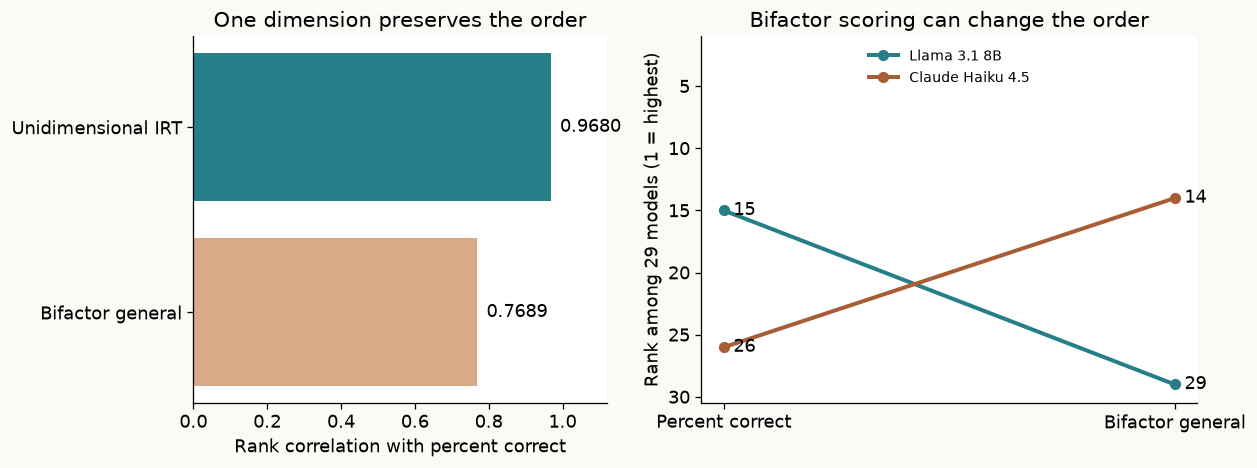

In [2]:
scores = pd.read_csv(HERE / "data/model_scores.csv")
correlations = pd.DataFrame([
    {"Scoring model": label,
     "Pearson r": pearsonr(scores.percent_correct, scores[column]).statistic,
     "Spearman rho": spearmanr(scores.percent_correct, scores[column]).statistic}
    for label, column in [("Unidimensional IRT", "unidimensional_score"),
                          ("Bifactor general", "bifactor_score")]
])
display(correlations.round(6))
display(scores.loc[scores.model_id.isin(["llama31-8b-16k8k", "claude-haiku-4-5"]),
                   ["display_name", "percent_rank", "bifactor_rank"]])
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].barh(correlations["Scoring model"], correlations["Spearman rho"], color=[TEAL, CLAY])
for y, value in enumerate(correlations["Spearman rho"]):
    axes[0].text(value + .025, y, f"{value:.4f}", va="center")
axes[0].set(xlim=(0, 1.12), xlabel="Rank correlation with percent correct", title="One dimension preserves the order")
axes[0].invert_yaxis()
for name, label, color in [("llama31-8b-16k8k", "Llama 3.1 8B", TEAL),
                            ("claude-haiku-4-5", "Claude Haiku 4.5", "#a85d36")]:
    row = scores.set_index("model_id").loc[name]
    axes[1].plot([0, 1], [row.percent_rank, row.bifactor_rank], "o-", color=color, lw=2.5, label=label)
    for x, rank in enumerate([row.percent_rank, row.bifactor_rank]):
        axes[1].annotate(f"{rank:g}", (x, rank), xytext=(6, 0), textcoords="offset points", va="center")
axes[1].set(xticks=[0, 1], xticklabels=["Percent correct", "Bifactor general"],
            ylim=(30.5, 1), ylabel="Rank among 29 models (1 = highest)", title="Bifactor scoring can change the order")
axes[1].legend(loc="upper center", frameon=False, fontsize=9)
fig.tight_layout()
show_figure(fig, "01_rank_comparison")

## 2. Load the selected fitted model
The original search used 20 starts. We load its selected state and keep all observed
responses. Original missing cells stay missing; the analysis uses MCAR as its working
missingness assumption. EM itself does not establish that assumption.

The bifactor response probability is
$$P(Y_{ij}=1)=\operatorname{logit}^{-1}\{a_j(g_i-b_j)+c_j s_{i,d(j)}\}.$$
Each item has a general slope \(a_j>0\) and one specific slope \(c_j\).
The original estimator integrates over item effects and estimates LLM coordinates
([Botter, 2026](https://doi.org/10.1080/15366367.2026.2720515)).

In [3]:
responses = pd.read_csv(HERE / "data/primary_responses.csv", index_col=0)
metadata = pd.read_csv(HERE / "data/item_metadata.csv", index_col=0).loc[responses.columns]
group = np.array([DOMAINS.index(category) for category in metadata.category])
fit_path = HERE / "fit/selected_q11.npz"
with np.load(fit_path, allow_pickle=False) as saved:
    state = {key: saved["state_" + key].copy()
             for key in ["scores", "tau", "means", "modes"]}
fit_info = json.loads((HERE / "fit/selected_q11.json").read_text())
settings = Settings(**fit_info["settings"])
estimator = ExtendedTransposed(responses.to_numpy(float), group, "bifactor", settings)
display(pd.Series({"LLMs": len(responses), "Items": responses.shape[1],
                   "Observed answers": int(responses.notna().sum().sum()),
                   "Selected start": fit_info["seed"],
                   "Fit SHA256": hashlib.sha256(fit_path.read_bytes()).hexdigest()}))

LLMs                                                               29
Items                                                             513
Observed answers                                                14760
Selected start                                                      8
Fit SHA256          3d56f382276cffdb5a795875da8d3321c710ae1a57f4ae...
dtype: object

### Read the bifactor paths
Each item rectangle receives a teal path from the general factor and a brown path
from its subject's residual factor. All eight residual factors are drawn separately;
the item ellipses include every question. The diagram shows the conventional
orthogonal reference. Our fixed-score implementation does not impose empirical
orthogonality on the estimated score columns.

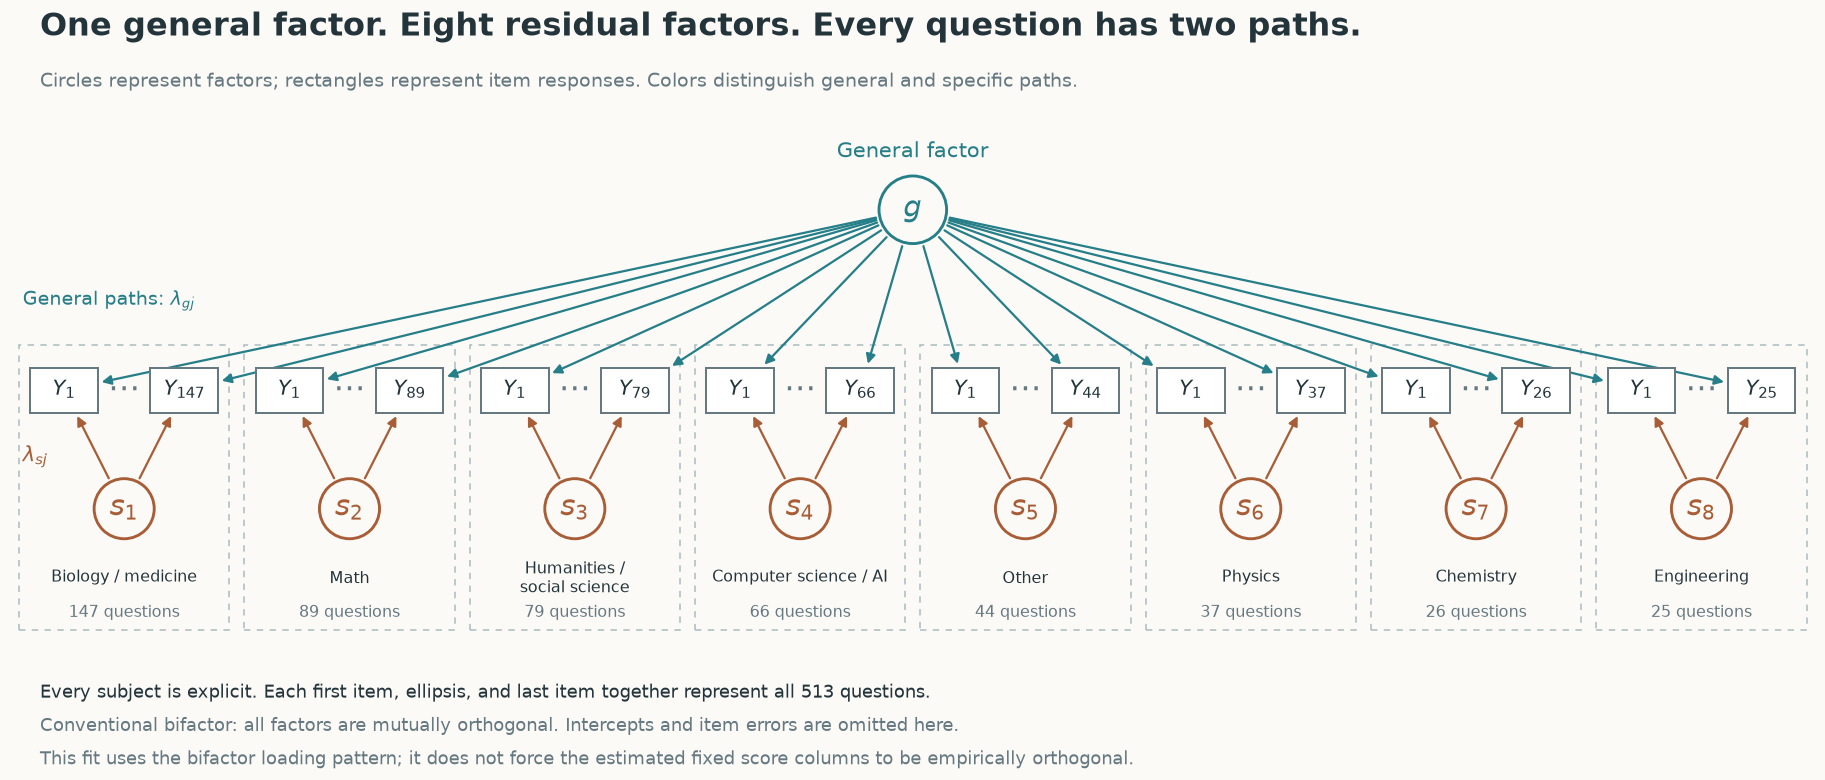

In [4]:
from ecv_diagrams import bifactor_paths, ecv_path
show_figure(bifactor_paths(np.bincount(group)), "04_bifactor_paths")

## 3. Recover slopes from the item distributions
An E-step computes item-effect distributions conditional on the saved fitted parameters.
It does **not** update those parameters. This can take a minute on a laptop as JAX compiles.
We use 17 quadrature points per dimension, matching the previous numerical check.

The point estimates are
$$\widehat a_j=E[\exp(\eta_{j1})\mid Y,\widehat\psi],\qquad
\widehat c_j=E[\eta_{j2}\mid Y,\widehat\psi].$$
Exponentiate **before** averaging: \(E[\exp(\eta)]\ne\exp(E[\eta])\).
These produce plug-in ECV indices, not posterior means of ECV or uncertainty intervals.

In [5]:
posterior = estimator.estep(state, points=17)
weights, nodes = posterior["weights"], posterior["nodes"]
a = np.sum(weights * np.exp(nodes[:, :, 1]), axis=1)
c = np.sum(weights * nodes[:, :, 2], axis=1)
display(pd.DataFrame({"General slope": a, "Specific slope": c}).describe().round(4))

,General slope,Specific slope
count,513.0000,513.0000
mean,1.0896,1.5033
std,0.3931,0.9804
min,0.4292,-1.1951
25%,0.7591,0.6840
50%,1.0326,1.4944
75%,1.3983,2.4364
max,2.7002,3.2978


## 4. Convert slopes to loadings, then calculate ECV
Under an **orthogonal, unit-variance factor reference**, the logistic latent-response
residual has variance \(\pi^2/3\). Standardize each item's response scale:
$$\lambda_{gj}=\frac{a_j}{\sqrt{a_j^2+c_j^2+\pi^2/3}},\qquad
\lambda_{sj}=\frac{c_j}{\sqrt{a_j^2+c_j^2+\pi^2/3}}.$$
The item index is
$$\mathrm{IECV}_j=\frac{\lambda_{gj}^2}{\lambda_{gj}^2+\lambda_{sj}^2}.
$$
For a subject's item set \(D\), use sums, not an ordinary average of item IECVs:
$$\mathrm{ECV}_{G,D}=\frac{\sum_{j\in D}\lambda_{gj}^2}
{\sum_{j\in D}(\lambda_{gj}^2+\lambda_{sj}^2)}.$$
The specific share within that subject is its complement. The reported ECVs use the
484 retained items from the saved fit.[^ecv-items]
See [Rodriguez et al. (2016)](https://doi.org/10.1037/met0000045).

In [6]:
# Apply the post-estimation inclusion rule before calculating any reported ECV.
retained = (a >= 0) & (c >= 0)
retained_metadata = metadata.loc[retained]
a, c = a[retained], c[retained]
group_ecv = group[retained]
scale = np.sqrt(a**2 + c**2 + np.pi**2 / 3)
lambda_g, lambda_s = a / scale, c / scale
item_ecv = lambda_g**2 / (lambda_g**2 + lambda_s**2)
items = retained_metadata.rename_axis("item_id").reset_index().copy()
items["general_slope"], items["specific_slope"] = a, c
items["general_loading_standardized"] = lambda_g
items["specific_loading_standardized"] = lambda_s
items["IECV_general"] = item_ecv
rows = []
for domain in DOMAINS + ["ALL ITEMS"]:
    use = np.ones(len(items), dtype=bool) if domain == "ALL ITEMS" else items.category.eq(domain).to_numpy()
    general = np.sum(lambda_g[use]**2)
    specific = np.sum(lambda_s[use]**2)
    rows.append({"Subject": domain, "Items": int(use.sum()),
                 "General ECV": general / (general + specific),
                 "Specific ECV": specific / (general + specific)})
subtests = pd.DataFrame(rows)
display(subtests.assign(**{column: subtests[column].map(lambda x: f"{x:.2%}")
                          for column in ["General ECV", "Specific ECV"]}))
# With raw slopes instead of standardized loadings, the overall weighting differs.
display(pd.Series({"Overall standardized-loading ECV": subtests.iloc[-1]["General ECV"],
                   "Overall unstandardized-slope ratio": np.sum(a*a) / np.sum(a*a+c*c)}))

,Subject,Items,General ECV,Specific ECV
0,Biology/Medicine,134,57.79%,42.21%
1,Math,89,16.32%,83.68%
2,Humanities/Social Science,79,43.43%,56.57%
3,Computer Science/AI,50,83.19%,16.81%
4,Other,44,18.80%,81.20%
5,Physics,37,18.47%,81.53%
6,Chemistry,26,26.01%,73.99%
7,Engineering,25,13.12%,86.88%
8,ALL ITEMS,484,33.79%,66.21%


Overall standardized-loading ECV      0.337933
Overall unstandardized-slope ratio    0.281118
dtype: float64

### Follow one item into the ECV ratio
For a concrete example, choose the math item closest to that subject's median IECV.
Its two standardized loading paths supply the two squared terms. Item error helps
determine the standardized loading scale, but is excluded from the common-variance
ratio. For subject or test ECV, sum the squared paths across the relevant items
before dividing.

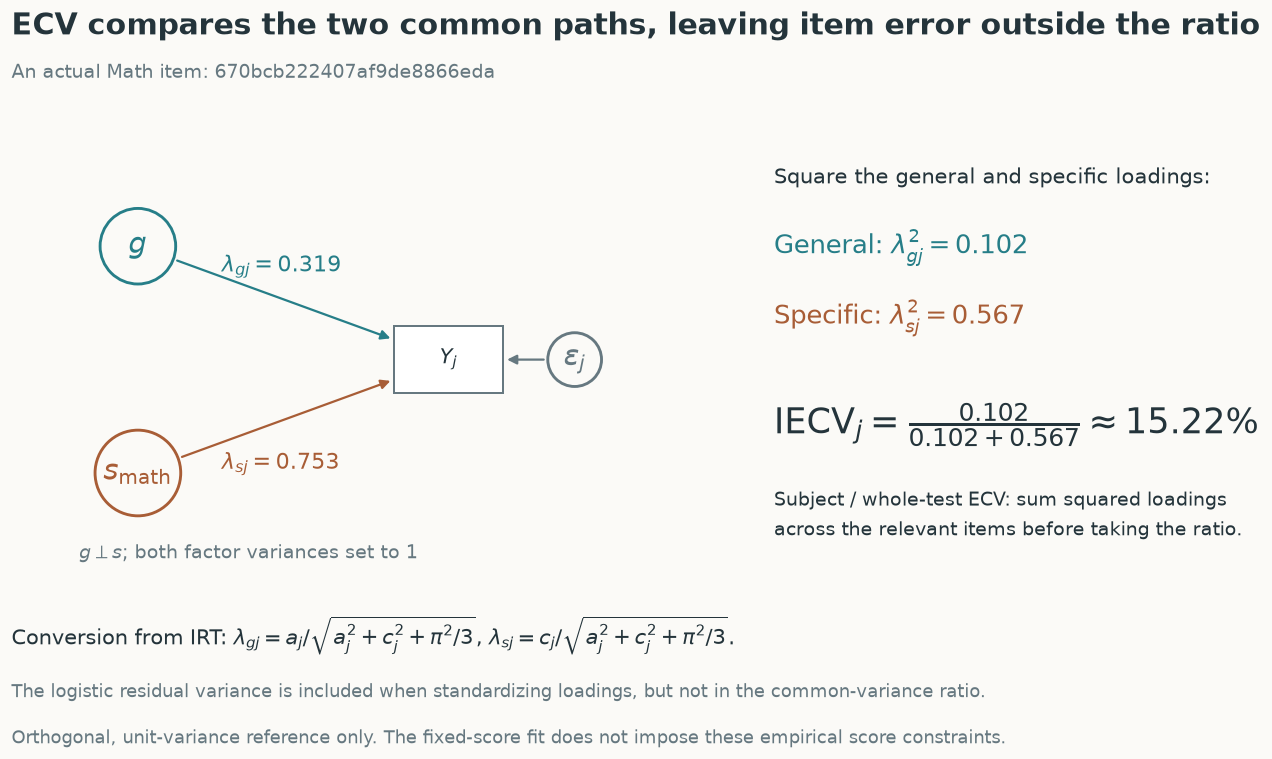

In [7]:
math_items = items.loc[items.category.eq("Math")]
example_index = (math_items.IECV_general - math_items.IECV_general.median()).abs().idxmin()
example_item = items.loc[example_index]
show_figure(ecv_path(example_item.general_slope, example_item.specific_slope,
                     example_item.category, example_item.item_id), "05_ecv_path")

## 5. Look inside the subjects
The colors represent general and specific shares of the same conventional common
loading denominator. They are not observed correct-answer percentages.

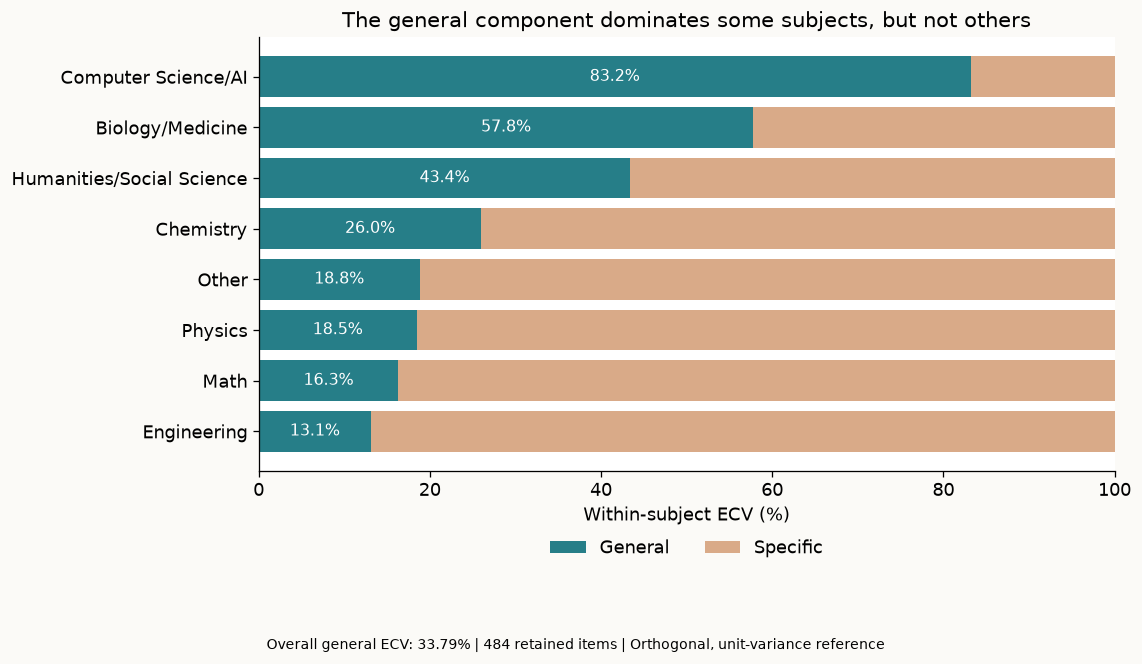

In [8]:
plot = subtests.iloc[:-1].sort_values("General ECV", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5.8))
y = np.arange(len(plot))
g, s = plot["General ECV"].to_numpy()*100, plot["Specific ECV"].to_numpy()*100
ax.barh(y, g, color=TEAL, label="General")
ax.barh(y, s, left=g, color=CLAY, label="Specific")
for j, value in enumerate(g):
    ax.text(value/2, j, f"{value:.1f}%", ha="center", va="center", color="white", fontsize=10)
ax.set(yticks=y, yticklabels=plot.Subject, xlim=(0, 100), xlabel="Within-subject ECV (%)",
       title="The general component dominates some subjects, but not others")
ax.invert_yaxis()
ax.legend(ncol=2, frameon=False, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.text(.5, .015, f"Overall general ECV: {subtests.iloc[-1]['General ECV']:.2%} | 484 retained items | Orthogonal, unit-variance reference", ha="center", fontsize=9)
fig.tight_layout(rect=(0,.10,1,1))
show_figure(fig, "02_subtest_ecv")

## 6. Look at the 484 retained items
IECV is unchanged by the common item-level response standardization, because its
scale factor cancels. A high value only describes the loading balance, not item
quality or content validity. The .80 line is a descriptive reference, not a verdict.

Median IECV         0.283512
Minimum IECV        0.021648
Maximum IECV        0.999575
Items above .80    77.000000
Items above .85    65.000000
dtype: float64

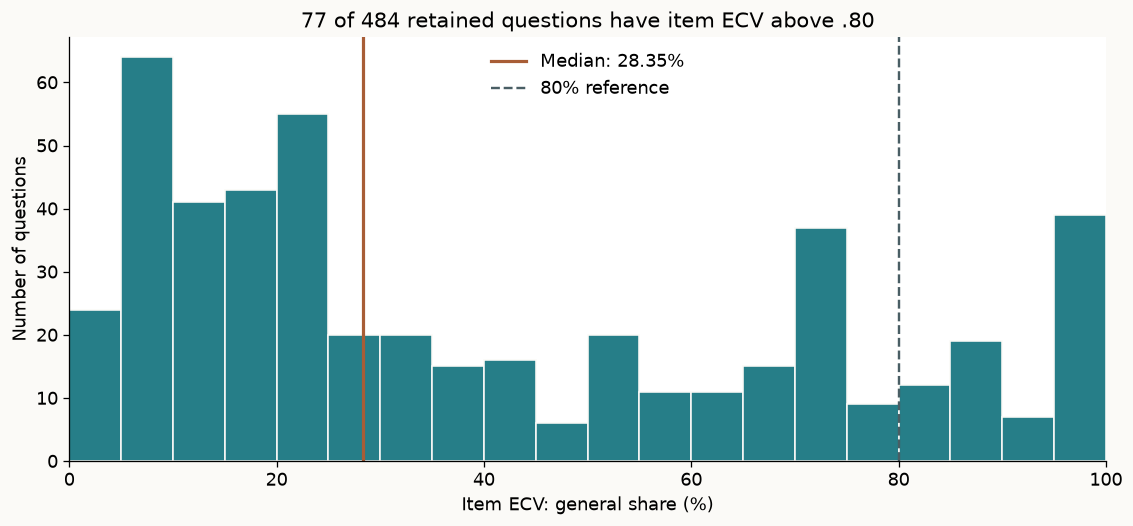

In [9]:
display(pd.Series({"Median IECV": np.median(item_ecv), "Minimum IECV": np.min(item_ecv),
                   "Maximum IECV": np.max(item_ecv), "Items above .80": int(np.sum(item_ecv > .80)),
                   "Items above .85": int(np.sum(item_ecv > .85))}))
fig, ax = plt.subplots(figsize=(10, 4.7))
ax.hist(item_ecv*100, bins=np.arange(0, 105, 5), color=TEAL, edgecolor="#fbfaf7")
ax.axvline(np.median(item_ecv)*100, color="#a85d36", lw=2, label=f"Median: {np.median(item_ecv):.2%}")
ax.axvline(80, color="#495e64", ls="--", lw=1.5, label="80% reference")
ax.set(xlim=(0,100), xlabel="Item ECV: general share (%)", ylabel="Number of questions",
       title=f"{np.sum(item_ecv > .80)} of {len(items)} retained questions have item ECV above .80")
ax.legend(frameon=False)
fig.tight_layout()
show_figure(fig, "03_item_ecv")

## 7. Read ECV with the item structure and score assumptions
ECV is a **unidimensionality check**, not a universal pass/fail rule.
[Andersson and Luo (2022)](https://doi.org/10.1177/01466216221084215) discuss the
.70–.80 range used in the literature and the need for estimation uncertainty.
[Reise et al. (2013)](https://doi.org/10.1177/0013164412449831) show that the
percentage of uncontaminated correlations (PUC) moderates some consequences of
multidimensionality. Here it is the proportion of item pairs in different subjects:
$$\mathrm{PUC}=1-\frac{\sum_d n_d(n_d-1)}{J(J-1)}.$$
A high PUC can make some unidimensional estimates more robust. It does not establish
that the general rankings here are valid.

In [10]:
counts = np.bincount(group_ecv)
puc = 1 - np.sum(counts*(counts-1)) / (len(group_ecv)*(len(group_ecv)-1))
coordinate_correlations = pd.DataFrame(np.corrcoef(state["scores"], rowvar=False),
                                      index=["General"]+DOMAINS, columns=["General"]+DOMAINS)
display(pd.Series({"PUC": puc,
    "Minimum general-specific score correlation": coordinate_correlations.iloc[0,1:].min(),
    "Maximum general-specific score correlation": coordinate_correlations.iloc[0,1:].max()}))
display(coordinate_correlations.iloc[0,1:].round(4))

PUC                                           0.834283
Minimum general-specific score correlation   -0.831760
Maximum general-specific score correlation   -0.491678
dtype: float64

Biology/Medicine            -0.8318
Math                        -0.6196
Humanities/Social Science   -0.6118
Computer Science/AI         -0.4917
Other                       -0.6729
Physics                     -0.5527
Chemistry                   -0.5517
Engineering                 -0.5749
Name: General, dtype: float64

The fixed score columns are strongly correlated, so their empirical variance includes
cross-terms. The usual orthogonal additive interpretation cannot be applied literally.
**33.79% is conditional on the stated reference, not an empirical percentage of LLM
performance explained by general intelligence.** No uncertainty interval has been
estimated. Shrinkage, model choice, and only 29 LLMs also matter.

## 8. Export the reproduced ECV tables
These exports contain the 484 retained items and their subject summaries.

In [11]:
# Save the reproduced diagnostics for inspection outside Jupyter.
result_folder = HERE / "results"
result_folder.mkdir(exist_ok=True)
items.to_csv(result_folder / "item_ecv.csv", index=False)
subtests.to_csv(result_folder / "subtest_ecv.csv", index=False)
correlations.to_csv(result_folder / "score_correlations.csv", index=False)

## 9. Keep the interpretation tied to the evidence
The rank comparison and loading-based diagnostics suggest that subject structure
deserves scrutiny before a single percentage is interpreted as general capability.
They do not certify the bifactor general coordinate as the uniquely correct ranking.
The fit uses 513 questions; the reported ECV diagnostics use 484 retained questions.
This is not the full official leaderboard.

The notebook recomputes conditional diagnostics from a saved fit. Separate execution
and numerical validation are documented in `notebook_verification.json`.

[^ecv-items]: The reported ECV calculations exclude all 29 items with negative posterior-mean specific slopes in the selected fit: 13 biology/medicine and 16 computer science/AI items. General slopes are positive by construction. Entire items are omitted from both the general and specific sums, leaving 484 items. The model is not refitted and the earlier rankings remain based on all 513 items. This is a post-estimation, data-dependent exclusion, not part of the standard ECV definition; negative loadings can otherwise contribute through their squares. For comparison, the full-item general ECV is 35.56%, versus 33.79% after exclusion. Signs are point estimates, not significance tests.

## References

- Andersson, B., & Luo, H. (2022). [Impact of sampling variability when estimating the explained common variance](https://doi.org/10.1177/01466216221084215). *Applied Psychological Measurement, 46*(4), 338–341.
- Botter, P. (2026). [Large language model benchmarks as measurement systems: Psychometric contributions and eight open problems](https://doi.org/10.1080/15366367.2026.2720515). *Measurement: Interdisciplinary Research and Perspectives*. Advance online publication.
- Reckase, M. D. (2009). [Multidimensional item response theory](https://doi.org/10.1007/978-0-387-89976-3). Springer.
- Reise, S. P., Scheines, R., Widaman, K. F., & Haviland, M. G. (2013). [Multidimensionality and structural coefficient bias in structural equation modeling: A bifactor perspective](https://doi.org/10.1177/0013164412449831). *Educational and Psychological Measurement, 73*(1), 5–26.
- Rodriguez, A., Reise, S. P., & Haviland, M. G. (2016). [Evaluating bifactor models: Calculating and interpreting statistical indices](https://doi.org/10.1037/met0000045). *Psychological Methods, 21*(2), 137–150.

Responses and category metadata: Sharma, M., Nadela, S., & Matteson, T. (2026).
[HLE Psychometrics](https://github.com/matrix-mayank/hle-psychometrics) [Data set and code].
Provenance is in `provenance.json`. No question text is redistributed.